# Laboratorio 02 · Embeddings faciales lineales

Universidad Católica del Norte · Machine Learning · 2026-02  
Docente: Dr. Juan Bekios Calfa

**Pregunta.** ¿Qué combinación de representación, dimensión y clasificador reconoce mejor fotografías nuevas de identidades conocidas en Olivetti y LFW?

El protocolo usa el entorno Conda del proyecto, una partición estratificada 75/25 con semilla 42 y las dimensiones 10, 20 y 30 fijadas antes del experimento. Abre este cuaderno desde la raíz del proyecto y ejecuta todas las celdas en orden.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import f1_score
from threadpoolctl import threadpool_limits

from src.almacen_modelos import AlmacenModelos
from src.config import DIR_FIGURAS, DIR_RESULTADOS, EMBEDDINGS
from src.datos import CargadorLFW, CargadorOlivetti, DivisorEstratificado
from src.embeddings import FabricaExtractores
from src.pipeline import PipelineExperimentos

REGENERAR = False
BASES = {"olivetti": CargadorOlivetti(), "lfw": CargadorLFW()}

## 1. Datos y particiones

Olivetti es balanceado. LFW conserva las 50 identidades con mayor frecuencia entre las elegibles. Las etiquetas reindexadas enlazan con el ID y el nombre del cargador original en los CSV de identidades. Cada fila de X corresponde a una foto aplanada en escala de grises. El split asigna fotos de las mismas identidades a TRAIN y TEST, con índices disjuntos.

In [2]:
conjuntos = {base: cargador.cargar() for base, cargador in BASES.items()}
divisor = DivisorEstratificado()
particiones = {base: divisor.dividir(conjunto) for base, conjunto in conjuntos.items()}
resumen = []

for base, conjunto in conjuntos.items():
    p = particiones[base]
    assert np.intersect1d(p.indices_train, p.indices_test).size == 0
    assert np.array_equal(np.unique(p.y_train), np.unique(p.y_test))
    assert np.array_equal(conjunto.images.reshape(conjunto.y.size, -1), conjunto.X)
    cuentas = np.bincount(conjunto.y)
    resumen.append({
        "base": base, "N": conjunto.y.size, "C": conjunto.n_clases,
        "H": conjunto.alto, "W": conjunto.ancho,
        "TRAIN": p.y_train.size, "TEST": p.y_test.size,
        "mín. por identidad": cuentas.min(), "máx. por identidad": cuentas.max(),
        "intensidad mín.": conjunto.X.min(), "intensidad máx.": conjunto.X.max(),
    })

display(pd.DataFrame(resumen).set_index("base"))

,N,C,H,W,TRAIN,TEST,mín. por identidad,máx. por identidad,intensidad mín.,intensidad máx.
base,,,,,,,,,,
olivetti,400,40,64,64,300,100,10,10,0.0,1.0
lfw,2773,50,62,47,2079,694,22,530,0.0,1.0


## 2. Tres representaciones a d=20

PCA conserva direcciones de alta varianza y centra usando la media de TRAIN. LDA usa las etiquetas de TRAIN y aprende direcciones que separan identidades en relación con su variación interna. Fisherfaces ajusta PCA en TRAIN y luego LDA sobre esas coordenadas. En la variante docente, la etapa intermedia retiene las mismas 20 coordenadas que la salida solicitada. La celda siguiente verifica las formas y la composición de las dos transformaciones.

In [3]:
fabrica = FabricaExtractores()
formas = []
with threadpool_limits(limits=1):
    for base, p in particiones.items():
        for nombre in EMBEDDINGS:
            ext = fabrica.crear(nombre, 20, conjuntos[base].n_clases)
            Z_train = ext.fit_transform(p.X_train, p.y_train)
            Z_test = ext.transform(p.X_test)
            assert Z_train.shape == (p.y_train.size, 20)
            assert Z_test.shape == (p.y_test.size, 20)
            if nombre == "fisherfaces":
                directa = ext.lda_.transform(ext.pca_.transform(p.X_test[:5]))
                np.testing.assert_allclose(ext.transform(p.X_test[:5]), directa)
            formas.append({"base": base, "embedding": nombre, "Z TRAIN": Z_train.shape, "Z TEST": Z_test.shape})
display(pd.DataFrame(formas))

,base,embedding,Z TRAIN,Z TEST
0,olivetti,pca,"(300, 20)","(100, 20)"
1,olivetti,lda,"(300, 20)","(100, 20)"
2,olivetti,fisherfaces,"(300, 20)","(100, 20)"
3,lfw,pca,"(2079, 20)","(694, 20)"
4,lfw,lda,"(2079, 20)","(694, 20)"
5,lfw,fisherfaces,"(2079, 20)","(694, 20)"


## 3. Experimentos completos y métricas

La celda lee la evidencia entregada cuando encuentra el protocolo, las tablas y las figuras compatibles con la huella de TRAIN y las versiones. Con salidas ausentes, o al activar **REGENERAR**, llama al mismo orquestador que usa la terminal. SVM, k-NN y árbol aprenden de Z de TRAIN. Las métricas se calculan con las predicciones sobre Z de TEST. Los tiempos corresponden al ajuste y la predicción del clasificador.

In [4]:
import sklearn

pipeline = PipelineExperimentos()
for base, conjunto in conjuntos.items():
    protocolo = DIR_RESULTADOS / f"protocolo_{base}.json"
    meta = json.loads(protocolo.read_text(encoding="utf-8")) if protocolo.exists() else {}
    esperadas = [DIR_RESULTADOS / f"{nombre}_{base}.csv" for nombre in (
        "resultados", "predicciones", "identidades", "particion", "reconstruccion_pca", "varianza_pca",
    )]
    esperadas.extend(DIR_FIGURAS / f"{metodo}_{base}_{nombre}_d20.png"
                     for metodo in ("tsne", "umap") for nombre in EMBEDDINGS)
    esperadas.extend(DIR_FIGURAS / f"{nombre}_{base}.png" for nombre in (
        "curva_pca", "eigenfaces", "reconstruccion_pca", "comparacion_accuracy",
        "comparacion_macro_f1", "comparacion_tiempo_s",
    ))
    referencia = ("pca", "svm") if base == "olivetti" else ("fisherfaces", "svm")
    esperadas.extend(
        DIR_FIGURAS / f"{prefijo}_{base}_{referencia[0]}_{referencia[1]}_d20.png"
        for prefijo in ("confusion", "ejemplos")
    )
    huella = AlmacenModelos(conjunto, particiones[base]).huella_train
    compatible = (
        meta.get("sha256_train") == huella
        and meta.get("versiones", {}).get("scikit-learn") == sklearn.__version__
        and all(ruta.is_file() for ruta in esperadas)
    )
    if REGENERAR or not compatible:
        getattr(pipeline, f"ejecutar_{base}")()

resultados = {
    base: pd.read_csv(DIR_RESULTADOS / f"resultados_{base}.csv") for base in conjuntos
}
for base, tabla in resultados.items():
    assert len(tabla) == 27
    print(base.upper())
    display(tabla[[
        "embedding", "d_pca", "d", "modelo", "accuracy", "macro_precision",
        "macro_recall", "macro_f1", "ajuste_s", "prediccion_s", "tiempo_s",
    ]].round(4))

OLIVETTI
LFW


,embedding,d_pca,d,modelo,accuracy,macro_precision,macro_recall,macro_f1,ajuste_s,prediccion_s,tiempo_s
0,pca,10.0,10,svm,0.86,0.8958,0.8583,0.8515,0.0380,0.0014,0.0394
1,pca,10.0,10,knn,0.78,0.8138,0.7750,0.7727,0.0007,0.0029,0.0036
2,pca,10.0,10,arbol,0.31,0.2860,0.3167,0.2667,0.0034,0.0001,0.0035
3,pca,20.0,20,svm,0.95,0.9625,0.9458,0.9465,0.0394,0.0014,0.0409
4,pca,20.0,20,knn,0.83,0.8754,0.8167,0.8257,0.0005,0.0042,0.0047
5,pca,20.0,20,arbol,0.36,0.3815,0.3667,0.3405,0.0058,0.0001,0.0059
6,pca,30.0,30,svm,0.98,0.9875,0.9792,0.9795,0.0431,0.0015,0.0446
7,pca,30.0,30,knn,0.84,0.8783,0.8250,0.8312,0.0005,0.0006,0.0010
8,pca,30.0,30,arbol,0.33,0.3315,0.3417,0.3030,0.0082,0.0002,0.0084
9,lda,NaN,10,svm,0.98,0.9833,0.9833,0.9800,0.0255,0.0013,0.0267


,embedding,d_pca,d,modelo,accuracy,macro_precision,macro_recall,macro_f1,ajuste_s,prediccion_s,tiempo_s
0,pca,10.0,10,svm,0.3300,0.2549,0.1621,0.1730,2.3096,0.0684,2.3780
1,pca,10.0,10,knn,0.1916,0.2004,0.1180,0.1259,0.0018,0.0088,0.0106
2,pca,10.0,10,arbol,0.2219,0.0914,0.0764,0.0652,0.0242,0.0003,0.0245
3,pca,20.0,20,svm,0.4409,0.3864,0.3005,0.3217,2.0742,0.0781,2.1523
4,pca,20.0,20,knn,0.2334,0.1970,0.1512,0.1498,0.0007,0.0094,0.0101
5,pca,20.0,20,arbol,0.2089,0.1035,0.0912,0.0828,0.0473,0.0003,0.0477
6,pca,30.0,30,svm,0.4856,0.4340,0.3654,0.3835,1.7514,0.0659,1.8173
7,pca,30.0,30,knn,0.2723,0.2661,0.1858,0.1927,0.0007,0.0055,0.0062
8,pca,30.0,30,arbol,0.2161,0.1222,0.0914,0.0889,0.0679,0.0003,0.0682
9,lda,NaN,10,svm,0.1758,0.1106,0.1053,0.1037,0.1346,0.0233,0.1579


In [5]:
filas = []
for base, tabla in resultados.items():
    for criterio in ("accuracy", "macro_f1"):
        maxima = tabla[tabla[criterio].eq(tabla[criterio].max())]
        filas.append(maxima.assign(criterio=criterio))
display(pd.concat(filas, ignore_index=True)[[
    "dataset", "criterio", "embedding", "modelo", "d", "accuracy", "macro_f1", "tiempo_s",
]].round(4))

for base, p in particiones.items():
    mayoritaria = int(np.bincount(p.y_train).argmax())
    ingenuo = np.full(p.y_test.size, mayoritaria)
    print(
        f"{base.upper()} · predecir siempre la clase más frecuente en TRAIN "
        f"({conjuntos[base].nombres_identidades[mayoritaria]}) → "
        f"accuracy {(ingenuo == p.y_test).mean():.2%}, "
        f"macro-F1 {f1_score(p.y_test, ingenuo, average='macro'):.4f}"
    )

OLIVETTI · predecir siempre la clase más frecuente en TRAIN (Identidad 0) → accuracy 2.00%, macro-F1 0.0010
LFW · predecir siempre la clase más frecuente en TRAIN (George W Bush) → accuracy 19.16%, macro-F1 0.0064


,dataset,criterio,embedding,modelo,d,accuracy,macro_f1,tiempo_s
0,olivetti,accuracy,lda,knn,10,0.9900,0.9900,0.0019
1,olivetti,macro_f1,lda,knn,10,0.9900,0.9900,0.0019
2,lfw,accuracy,pca,svm,30,0.4856,0.3835,1.8173
3,lfw,macro_f1,fisherfaces,svm,30,0.4841,0.3957,1.2006


El máximo observado resume la grilla fija. Para seleccionar una configuración de uso posterior, se requiere validación dentro de TRAIN con el embedding ajustado de nuevo en cada fold. El costo medido cubre una corrida de cada clasificador y puede variar con el equipo y la carga del sistema.

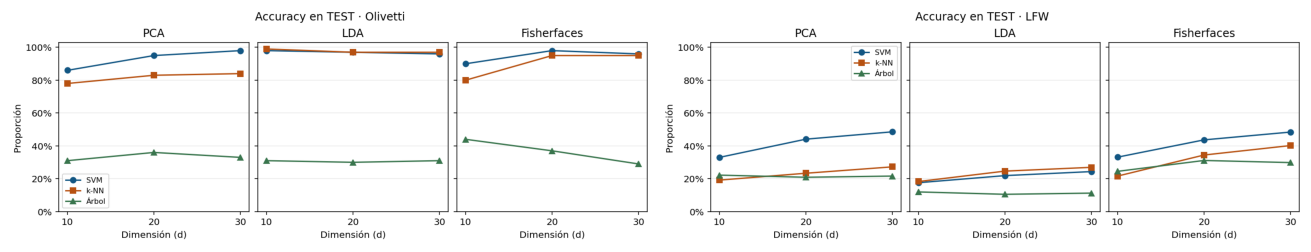

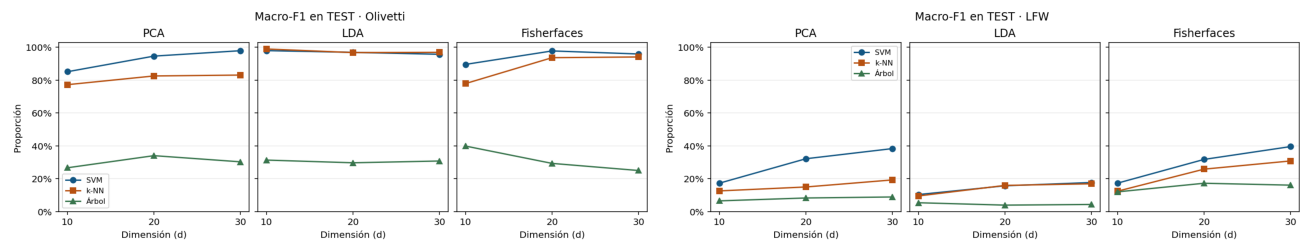

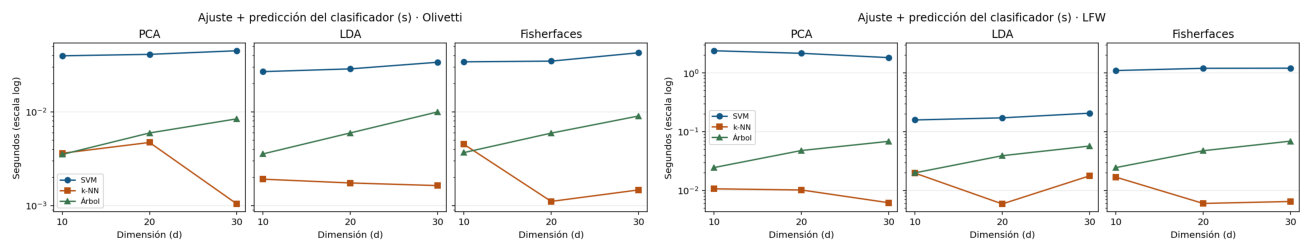

In [6]:
def panel(rutas, columnas=2, ancho=12):
    filas = (len(rutas) + columnas - 1) // columnas
    fig, ejes = plt.subplots(
        filas, columnas, figsize=(ancho, ancho * filas / columnas * 0.77),
        layout="constrained", squeeze=False,
    )
    for ax in ejes.ravel():
        ax.axis("off")
    for ax, ruta in zip(ejes.ravel(), rutas):
        ax.imshow(plt.imread(DIR_FIGURAS / ruta))
    plt.show()
    plt.close(fig)

for metrica in ("accuracy", "macro_f1", "tiempo_s"):
    panel([f"comparacion_{metrica}_{base}.png" for base in conjuntos], ancho=13)

## 4. Varianza, eigenfaces y reconstrucción

Cada fila de la tabla utiliza la misma base PCA de TRAIN y conserva un prefijo de sus componentes. El ECM del ejemplo usa la primera foto de TEST en el orden de índices. El ECM medio promedia todas las fotos reservadas. El cálculo usa la reconstrucción lineal completa y la figura muestra intensidades en la escala común [0,1].

OLIVETTI
LFW


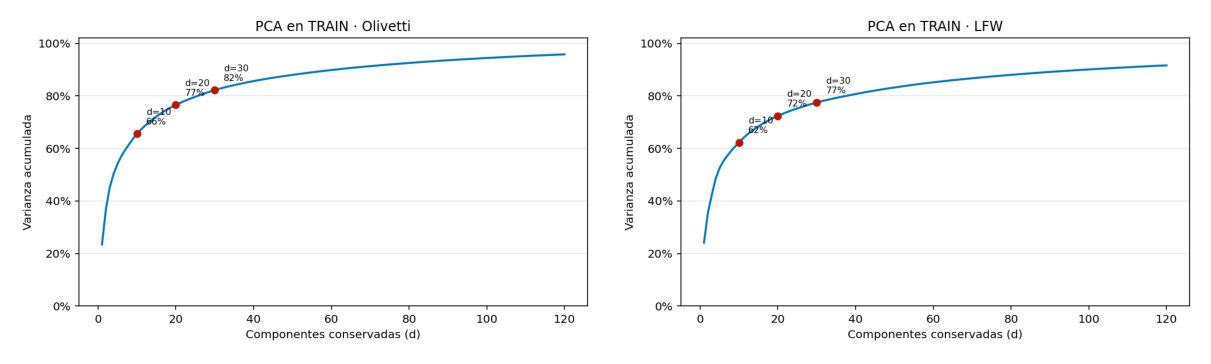

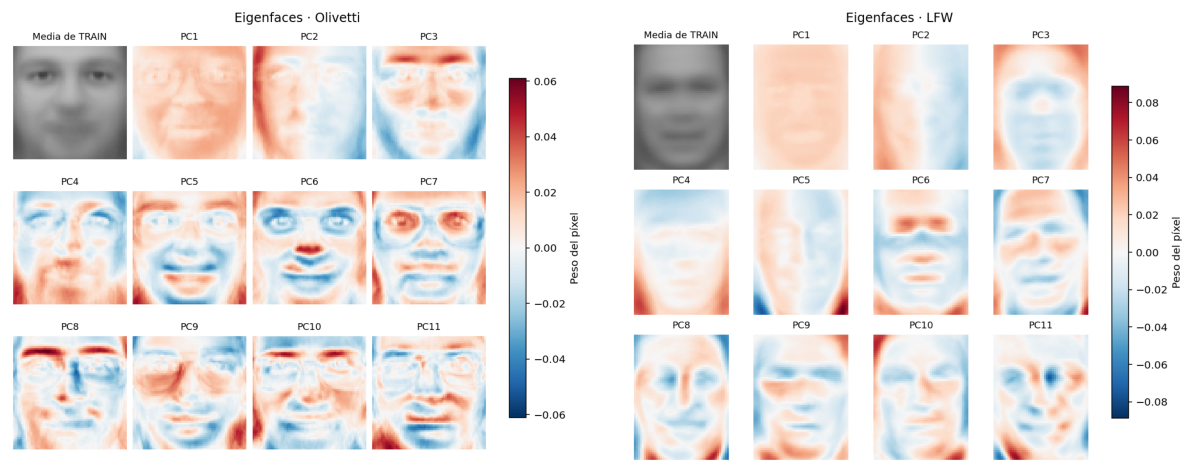

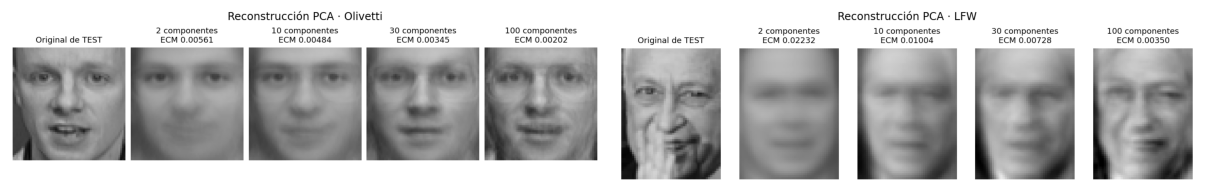

,d,fila_ejemplo,varianza_acumulada_train,ecm_ejemplo,ecm_medio_test
0,2,0,0.367713,0.005611,0.011830
1,10,0,0.655289,0.004835,0.007001
2,30,0,0.821762,0.003454,0.004288
3,100,0,0.943996,0.002019,0.002574


,d,fila_ejemplo,varianza_acumulada_train,ecm_ejemplo,ecm_medio_test
0,2,2,0.354745,0.022315,0.016284
1,10,2,0.622759,0.010042,0.009751
2,30,2,0.774517,0.007278,0.005984
3,100,2,0.900464,0.003498,0.002927


In [7]:
panel([f"curva_pca_{base}.png" for base in conjuntos])
panel(["eigenfaces_olivetti.png", "eigenfaces_lfw.png"])
panel([f"reconstruccion_pca_{base}.png" for base in conjuntos])
for base in conjuntos:
    print(base.upper())
    display(pd.read_csv(DIR_RESULTADOS / f"reconstruccion_pca_{base}.csv").round(6))

En Olivetti, al pasar de 20 a 30 componentes, la varianza retenida crece de 76,54 % a 82,18 %. El macro-F1 del árbol sobre PCA baja de 0,3405 a 0,3030 en ese mismo tramo. La compresión, la reconstrucción y la capacidad de reconocer identidades responden a objetivos distintos.

## 5. Vecindades de TRAIN

t-SNE usa perplejidad 30, inicialización PCA y 1.000 iteraciones. UMAP usa 15 vecinos, distancia mínima 0,1 e inicialización espectral. Ambos utilizan distancia euclidiana, semilla 42 y las coordenadas de d=20. Los ejes son propios de cada mapa. El gráfico de UMAP para LDA en LFW emitió un aviso de conectividad durante su inicialización espectral. La superposición y las islas del mapa se interpretan como evidencia exploratoria del TRAIN.

OLIVETTI
LFW


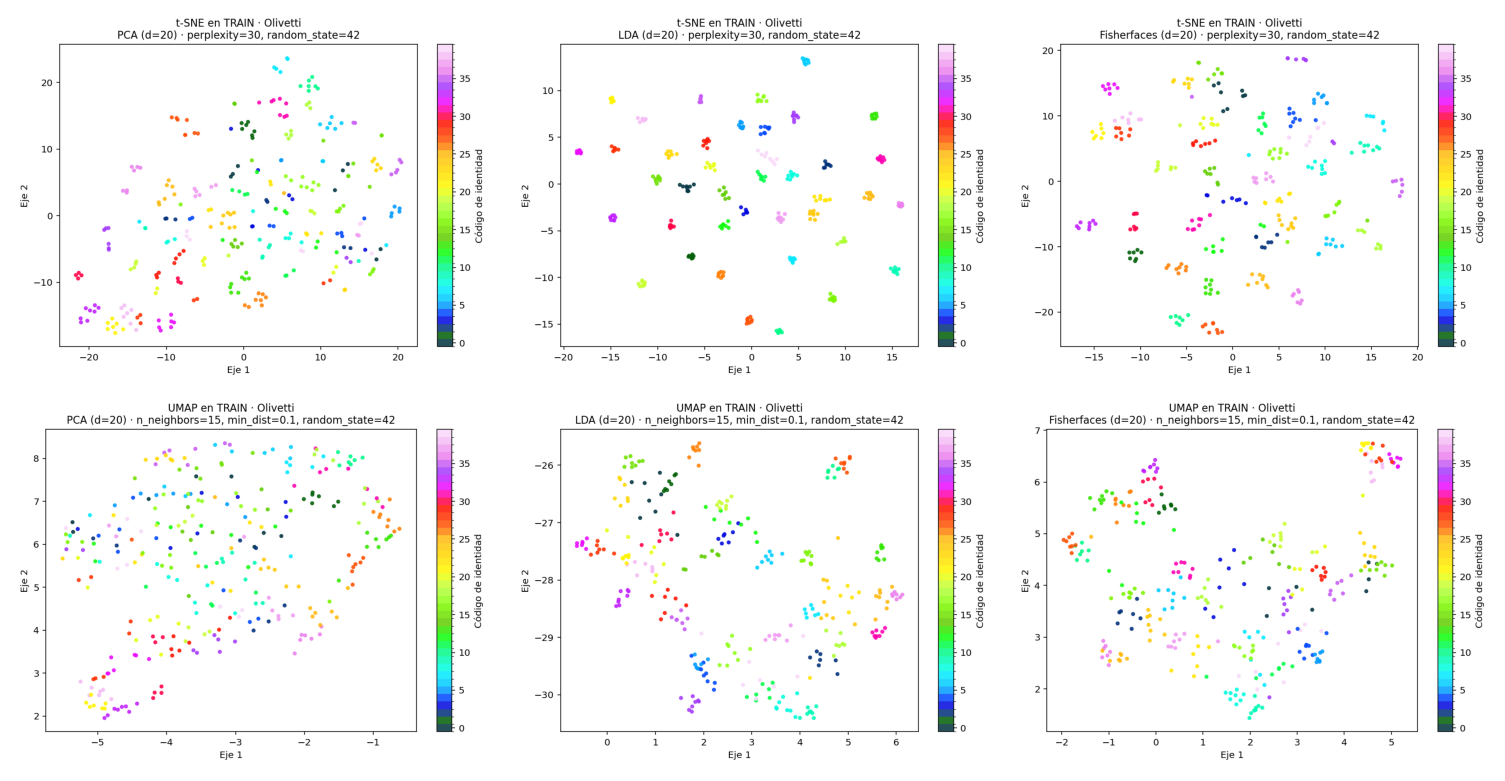

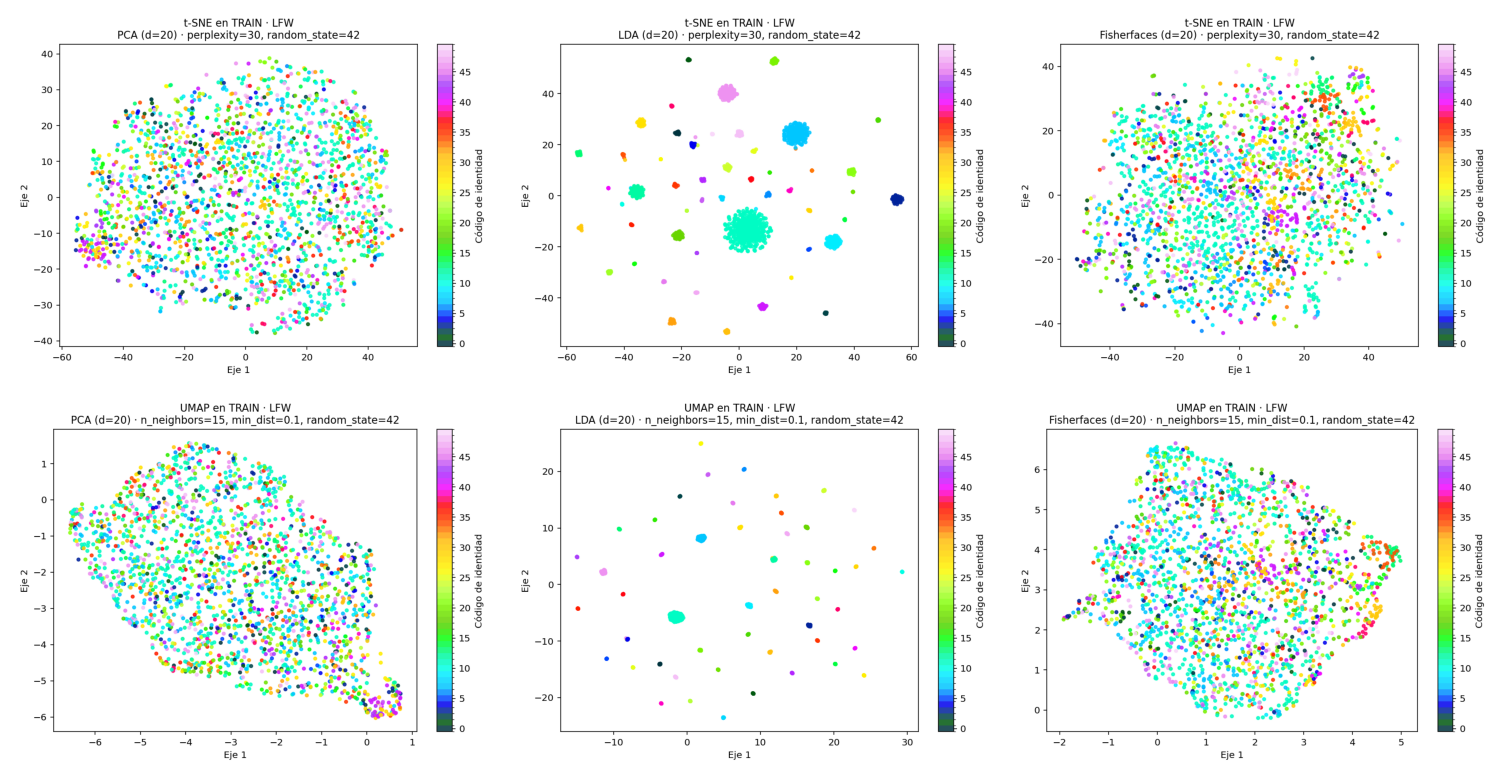

In [8]:
for base in conjuntos:
    print(base.upper())
    panel(
        [f"{metodo}_{base}_{embedding}_d20.png"
         for metodo in ("tsne", "umap") for embedding in EMBEDDINGS],
        columnas=3, ancho=15,
    )

## 6. Confusiones en una dimensión común

Para aislar el cambio de clasificador se fija d=20, PCA en Olivetti y Fisherfaces en LFW. Los conteos de la tabla conservan la dirección real → predicha. Las imágenes ilustran aciertos y errores de los SVM de referencia.

OLIVETTI · 1 pares direccionales compartidos por los tres clasificadores
LFW · 76 pares direccionales compartidos por los tres clasificadores


,modelo,arbol,knn,svm,suma
id_real,id_predicho,,,,
Identidad 3,Identidad 24,3,0,0,3
Identidad 14,Identidad 24,3,0,0,3
Identidad 20,Identidad 24,3,0,0,3
Identidad 25,Identidad 24,1,1,1,3
Identidad 29,Identidad 24,3,0,0,3


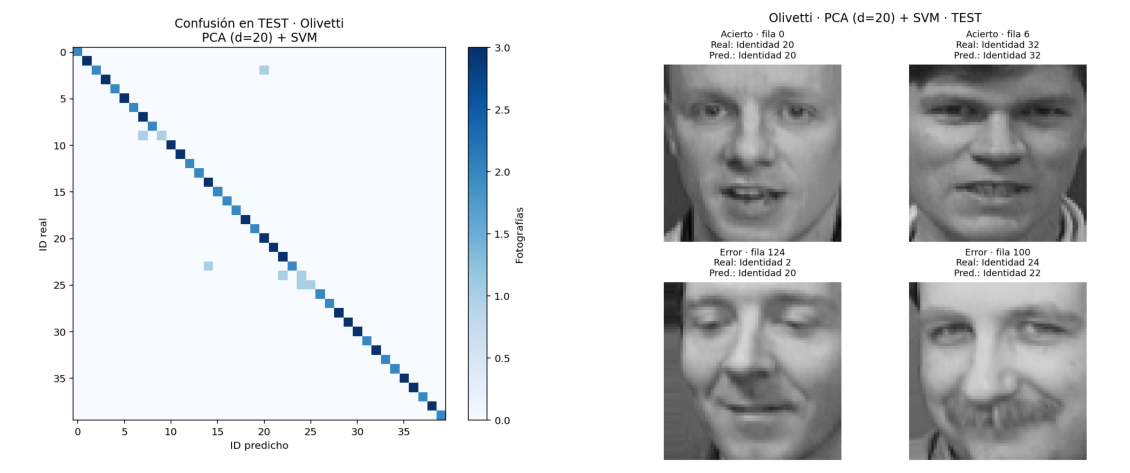

,modelo,arbol,knn,svm,suma
id_real,id_predicho,,,,
George W Bush,Colin Powell,8,18,7,33
Colin Powell,George W Bush,7,9,11,27
Tony Blair,George W Bush,4,11,7,22
Jacques Chirac,George W Bush,7,4,7,18
John Ashcroft,George W Bush,5,5,8,18


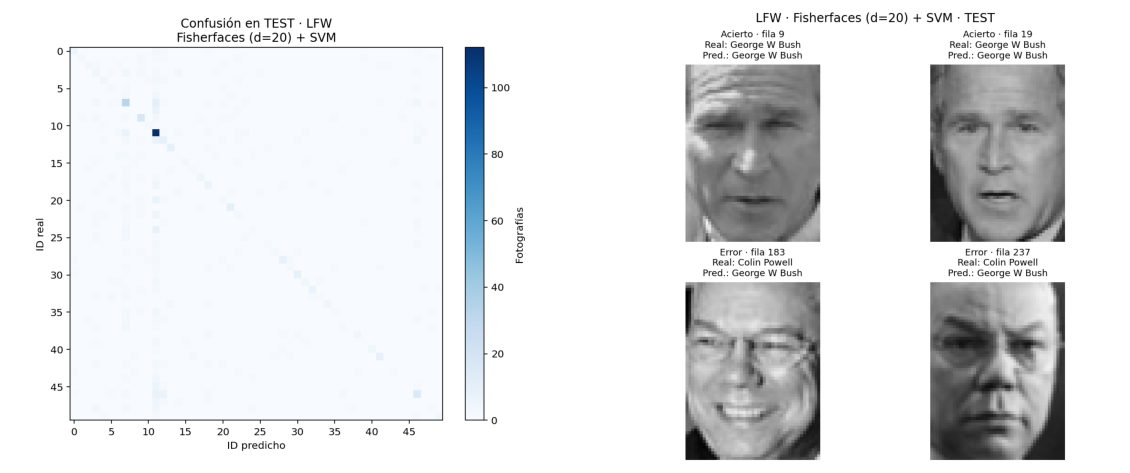

In [9]:
for base, embedding in {"olivetti": "pca", "lfw": "fisherfaces"}.items():
    pred = pd.read_csv(DIR_RESULTADOS / f"predicciones_{base}.csv")
    nombres = pd.read_csv(DIR_RESULTADOS / f"identidades_{base}.csv").set_index("id").nombre
    errores = pred.query("d == 20 and embedding == @embedding and id_real != id_predicho")
    pares = errores.groupby(["id_real", "id_predicho", "modelo"]).size().unstack(fill_value=0)
    pares["suma"] = pares.sum(axis=1)
    compartidos = (pares[["svm", "knn", "arbol"]] > 0).all(axis=1).sum()
    print(f"{base.upper()} · {compartidos} pares direccionales compartidos por los tres clasificadores")
    display(pares.nlargest(5, "suma").rename(index=nombres.to_dict()))
    panel([f"confusion_{base}_{embedding}_svm_d20.png", f"ejemplos_{base}_{embedding}_svm_d20.png"])

Los tres clasificadores sobre PCA confunden la misma foto 334 (ID 25 → ID 24) en Olivetti. En LFW, Fisherfaces a d=20 concentra confusiones en identidades frecuentes. Por ejemplo, Colin Powell → George W Bush aparece 11, 9 y 7 veces en SVM, k-NN y árbol, respectivamente. Las fotos de Powell seleccionadas muestran cambios en gesto, lentes e iluminación. Estas observaciones permiten formular hipótesis que requerirían anotaciones o controles adicionales.

## 7. Conclusiones de la ejecución entregada

- **Olivetti.** LDA + k-NN a d=10 obtuvo 99 de 100 aciertos y macro-F1 de 0,9900. Fisherfaces supera a PCA con k-NN en las tres dimensiones; con SVM la relación cambia en d=30.
- **LFW.** Fisherfaces + SVM a d=30 obtuvo el mayor macro-F1 (0,3957). PCA + SVM a d=30 acertó 337 de 694 fotos, una más que Fisherfaces + SVM. La comparación ilustra el efecto de ponderar por identidad frente a ponderar por foto.
- **Dimensión y costo.** Fisherfaces + k-NN a d=30 en LFW es un punto de comparación con un costo de clasificador menor y macro-F1 de 0,3083. El valor depende del objetivo y deja pendiente medir todo el proceso desde los píxeles.
- **Alcance.** Son evaluaciones de identidades conocidas con una sola partición, imágenes recortadas y conjuntos con condiciones diferentes. Los resultados corresponden a estas bases y al uso académico.

Fotografías de Olivetti: AT&T Laboratories Cambridge, vía scikit-learn. Fotografías de LFW: Huang et al., UMass Amherst, versión funneled vía scikit-learn. Las referencias completas están en el informe.